In [109]:
from pathlib import Path

# enable ipympl widgets for zoom
# %matplotlib widget
#%matplotlib inline
import seaborn as sns
import matplotlib.pyplot as plt
#from matplotlib.ticker import FixedLocator
from matplotlib.ticker import NullLocator, AutoMinorLocator, MultipleLocator
from matplotlib.lines import Line2D
import pandas as pd
from pint import UnitRegistry, set_application_registry
import pint_pandas  # needed for initialization
import numpy as np
import statsmodels.formula.api as smf
import statsmodels.api as sm
from scipy.stats import skew, kurtosis
from scipy.stats import levene, median_abs_deviation, spearmanr

ureg = UnitRegistry()
set_application_registry(ureg)

In [110]:
#sns.set_theme()
#sns.set_theme(style="white")
#sns.set_theme(style="whitegrid")
#sns.set_theme(style="ticks")
sns.set_theme(
    style="ticks",
    context="paper",
    rc={
        "axes.linewidth": 0.8,
        "xtick.direction": "out",
        "ytick.direction": "out"
    }
)

In [78]:
def import_dataset(filename: Path):
    df = pd.read_csv(filename, header=[0, 1])

    names = df.columns.get_level_values(0)
    units = df.columns.get_level_values(1)

    df.columns = names  # flatten
    if 'timestamp' in df.columns:
        df["timestamp"] = pd.to_datetime(df["timestamp"], format="ISO8601")
    for col, unit in zip(names, units):  # apply units
        if unit != "No Unit":
            df[col] = df[col].astype(f"pint[{unit}]")

    return df

In [111]:
experiment_folder = Path("../data_processing")
resources_folder = experiment_folder / "resources"
df = import_dataset(resources_folder / "tp_full_large.csv")

In [80]:
def extract_comp_dataframe(df: pd.DataFrame, threading: str, mode: str) -> pd.DataFrame:
    comp = df.copy()
    comp = comp[comp["mode"] == mode]
    comp = comp[comp["threading"] == threading]
    return comp

In [81]:
def calculate_base(df: pd.DataFrame) -> pd.DataFrame:
    reference = 1 * ureg.byte / ureg.second
    normalized = df["throughput"] / reference
    df["log_throughput"] = np.log(normalized).pint.magnitude    
    return comp

In [82]:
def fit_two_way_model(data: pd.DataFrame, response):
    formula = f"""
    {response} ~ (
        C(host, Sum)
        + C(tool, Sum)
        + C(dataset, Sum)
        + C(strength, Sum)
    )**2
    """

    return smf.ols(
        formula=formula,
        data=data
    ).fit()

In [83]:
def fit_higher_order_models(data: pd.DataFrame, response):
    three_way_formula = f"""
        {response} ~ (
            C(host, Sum)
            + C(tool, Sum)
            + C(dataset, Sum)
            + C(strength, Sum)
        )**3
    """

    full_formula = f"""
        {response} ~
        C(host, Sum) *
        C(tool, Sum) *
        C(dataset, Sum) *
        C(strength, Sum)
    """

    three_way_model = smf.ols(
        formula=three_way_formula,
        data=data
    ).fit()

    full_model = smf.ols(
        formula=full_formula,
        data=data
    ).fit()

    return three_way_model, full_model

In [106]:
def plot_model_diagnostics(model, kind, title):
    rmse = np.sqrt(model.mse_resid)

    print(
        f"{kind.capitalize()}: {title}: "
        f"R²={model.rsquared:.6f}, "
        f"RMSE={rmse:.6f}"
    )

    diagnostics = pd.DataFrame({
        "fitted": full_model.fittedvalues,
        "residual": full_model.resid,
    })    

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    sns.residplot(
        data=diagnostics,
        x="fitted",
        y="residual",
        lowess=True,
        scatter_kws={"alpha": 0.2, "s": 8},
        line_kws={"color": "red"},
        ax=axes[0]
    )
    axes[0].axhline(0, color="black", linestyle="--")
    axes[0].set_xlabel(f"Fitted log {kind}")
    axes[0].set_ylabel("Residual")
    axes[0].set_title("Residuals vs fitted")

    sm.qqplot(
        diagnostics["residual"],
        line="45",
        fit=True,
        ax=axes[1]
    )
    axes[1].set_title("Q–Q plot")

    sns.histplot(
        data=diagnostics,
        x="residual",
        bins=60,
        kde=True,
        ax=axes[2]
    )
    axes[2].axvline(0, color="black", linestyle="--", linewidth=1)
    axes[2].set_title("Distribution of resifuals")
    axes[2].set_xlabel("Residue")    

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

In [98]:
comp = extract_comp_dataframe(df, "single", "compress")
comp = calculate_base(comp)

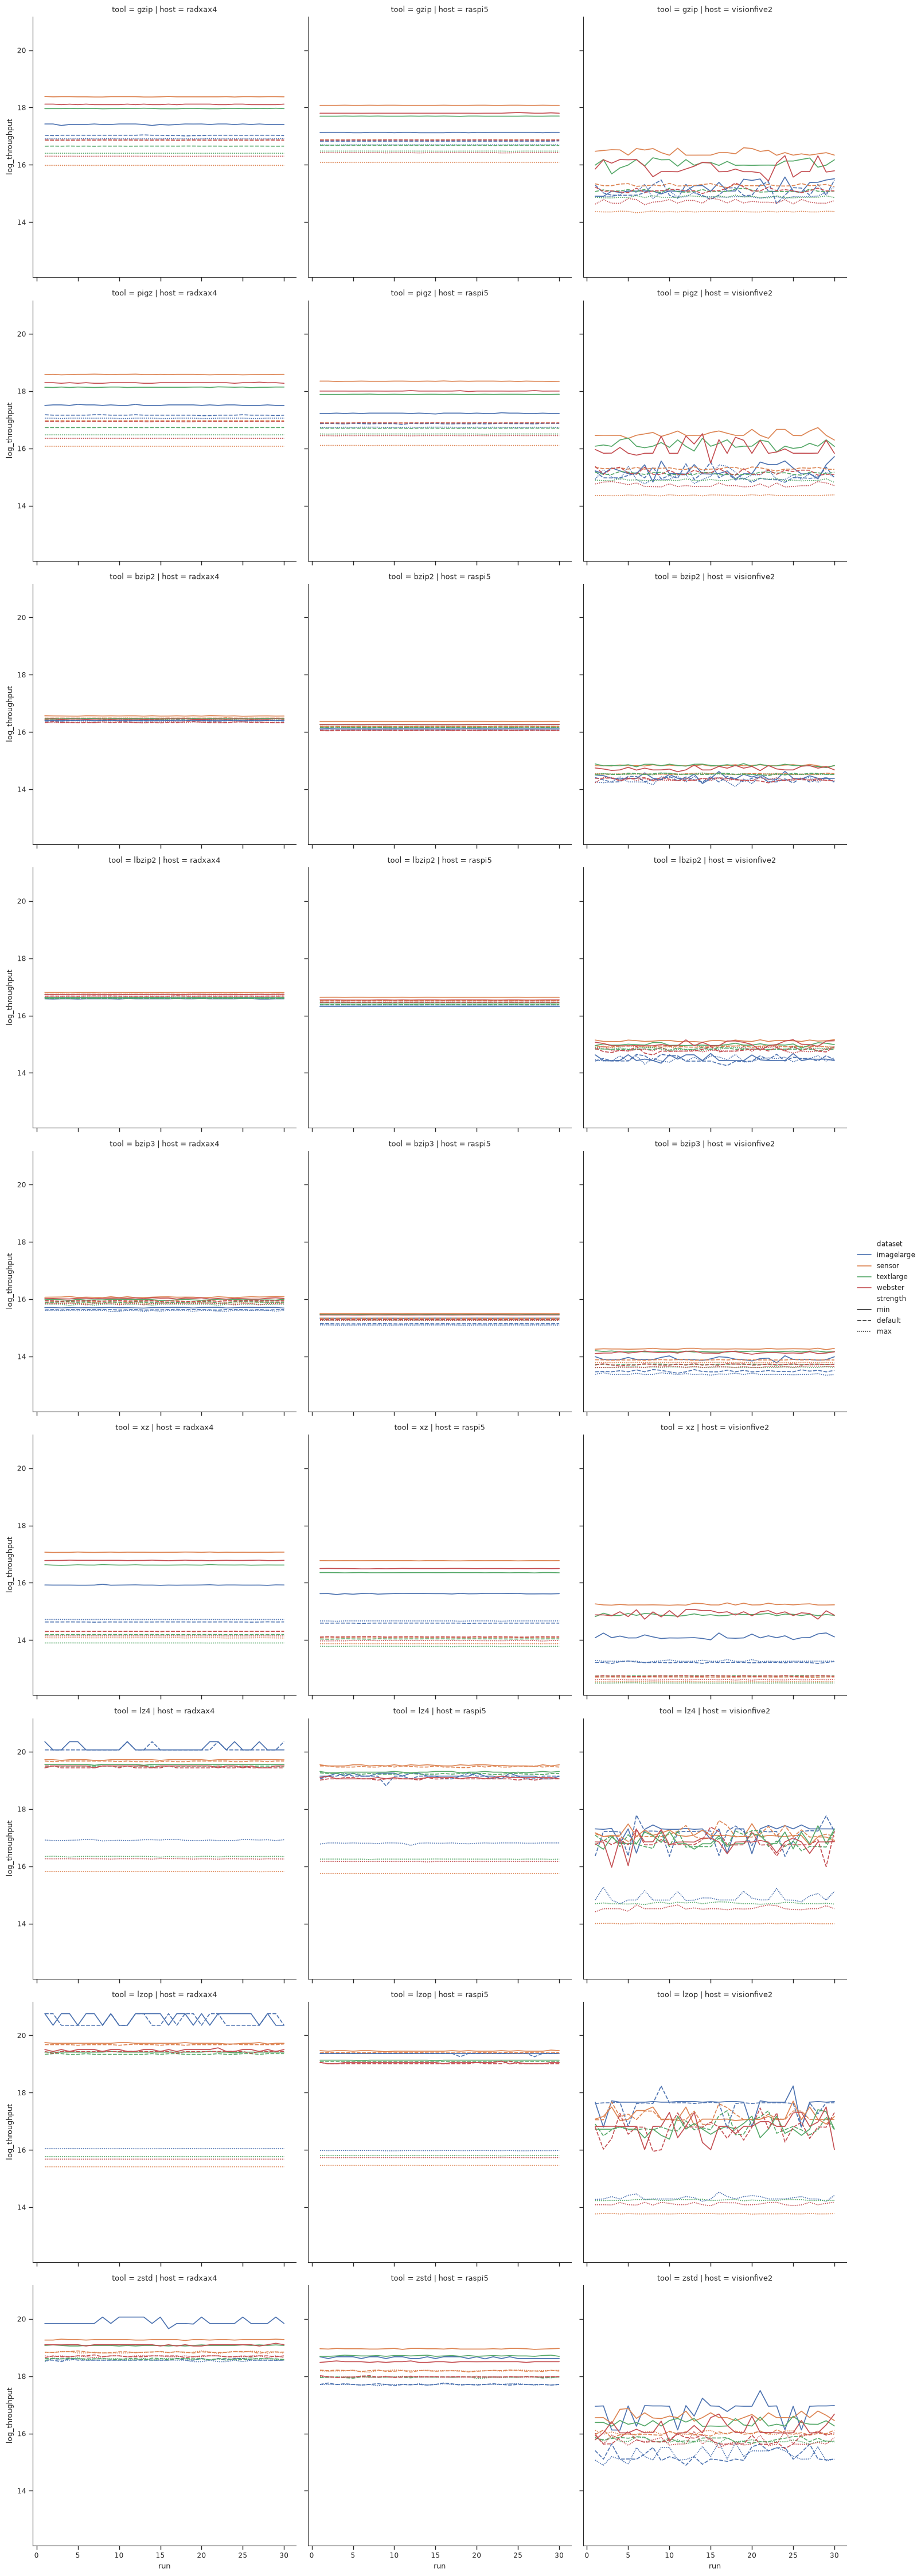

In [99]:
sns.relplot(
    data=comp,
    x="run",
    y="log_throughput",
    hue="dataset", 
    style="strength", 
    col="host",
    row="tool",
    kind="line",
)

Throughput: full model: R²=0.997647, RMSE=0.083789


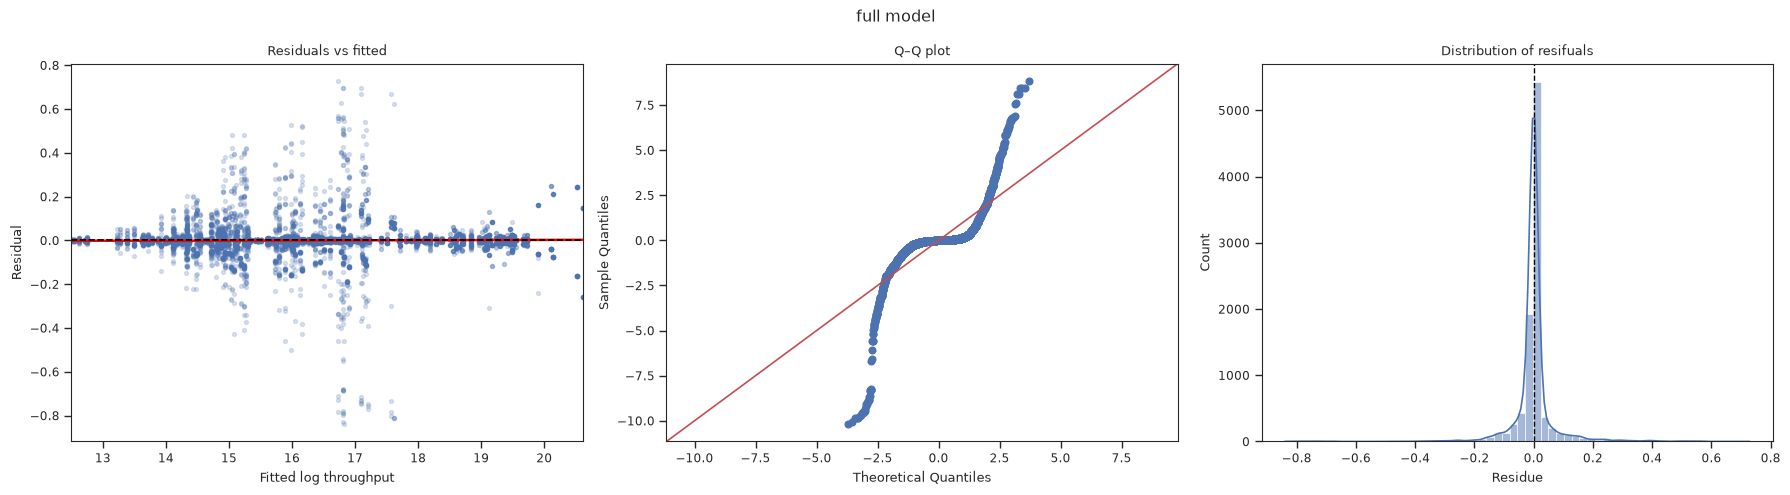

In [108]:
two_way_model = fit_two_way_model(comp,"log_throughput")
three_way_model, full_model = fit_higher_order_models(comp, "log_throughput")

plot_model_diagnostics(full_model, "throughput", "full model")

Number of configurations: 324

Distribution of residual standard deviations:
count    324.000000
mean       0.040794
std        0.073300
min        0.000000
25%        0.002943
50%        0.009921
75%        0.031201
max        0.386040
Name: residual_sd, dtype: float64

90th/10th percentile ratio: 76.129

Brown-Forsythe test:
Statistic: 14.437898
p-value:   0

Spearman association:
rho:     0.028210
p-value: 0.612915


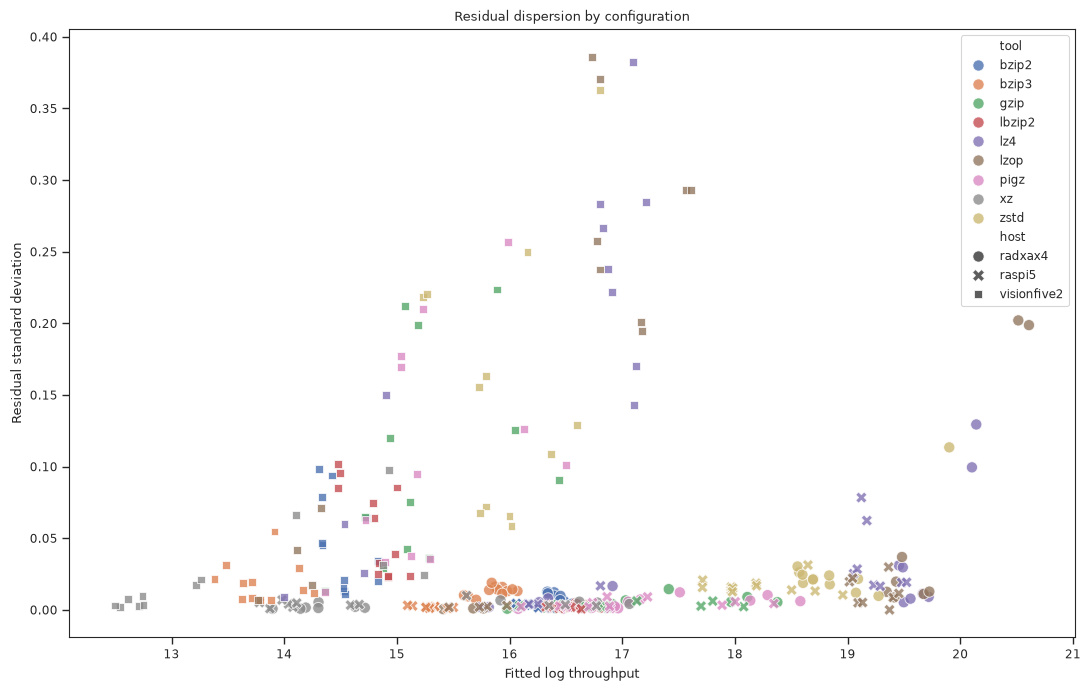

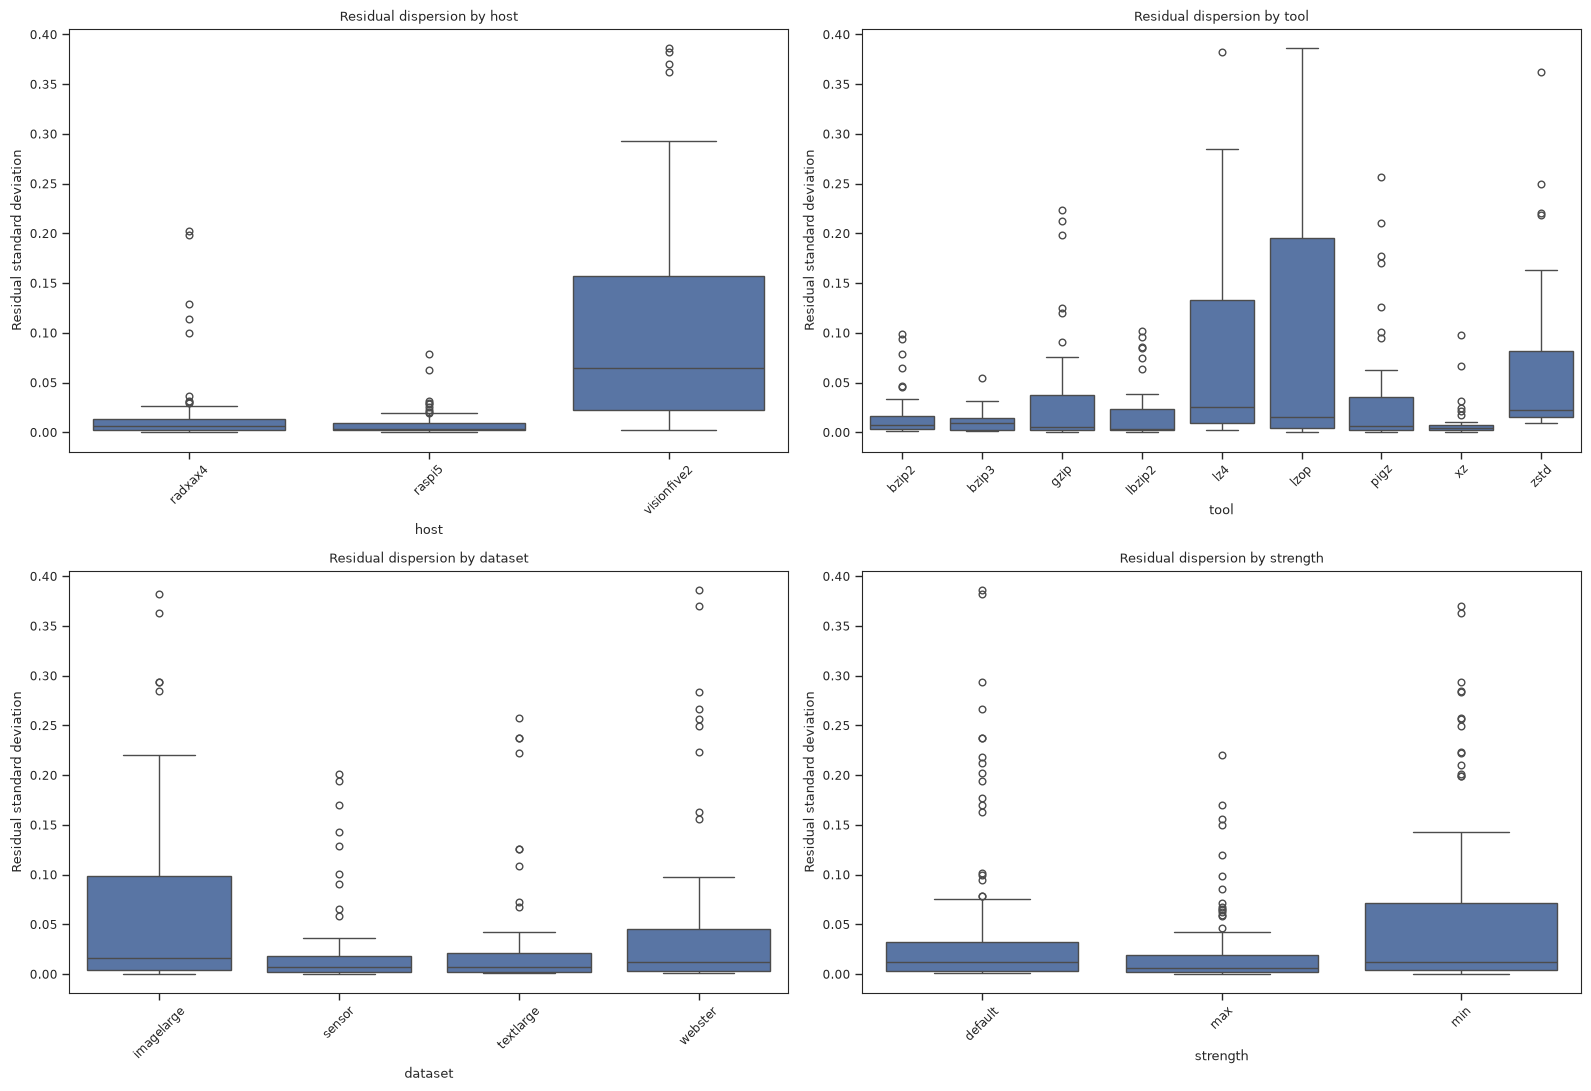


Residual dispersion by host:
             count    median      mean       min       max
host                                                      
visionfive2    108  0.064640  0.099606  0.002223  0.386040
radxax4        108  0.006613  0.015182  0.000499  0.202032
raspi5         108  0.003103  0.007595  0.000000  0.078355

Residual dispersion by tool:
        count    median      mean       min       max
tool                                                 
lz4        36  0.025433  0.080048  0.001895  0.382089
zstd       36  0.022799  0.066963  0.009717  0.362716
lzop       36  0.014900  0.083027  0.000000  0.386040
bzip3      36  0.009786  0.011403  0.001085  0.054669
bzip2      36  0.007000  0.018639  0.001262  0.098438
pigz       36  0.006252  0.039503  0.000703  0.256777
gzip       36  0.005439  0.036708  0.000777  0.223575
xz         36  0.003927  0.010405  0.000765  0.097722
lbzip2     36  0.003164  0.020454  0.000660  0.101957

Residual dispersion by dataset:
            count 

In [115]:
factors = ["host", "tool", "dataset", "strength"]

# 4.2.1 Create a separate diagnostics data frame
model_rows = full_model.model.data.row_labels

diagnostics = (
    df.loc[model_rows, factors]
    .reset_index(drop=True)
    .copy()
)

diagnostics["fitted"] = np.asarray(
    full_model.fittedvalues
)
diagnostics["residual"] = np.asarray(
    full_model.resid
)

# 4.2.2 Calculate residual dispersion for each configuration
cell_variance = (
    diagnostics
    .groupby(factors, observed=True)
    .agg(
        n=("residual", "size"),
        fitted=("fitted", "mean"),
        residual_sd=("residual", "std"),
        residual_mad=(
            "residual",
            lambda x: median_abs_deviation(
                x,
                scale="normal"
            )
        ),
        residual_rmse=(
            "residual",
            lambda x: np.sqrt(np.mean(np.square(x)))
        ),
    )
    .reset_index()
)

print(f"Number of configurations: {len(cell_variance)}")
print("\nDistribution of residual standard deviations:")
print(cell_variance["residual_sd"].describe())

q10, q90 = cell_variance["residual_sd"].quantile([0.10, 0.90])

print(f"\n90th/10th percentile ratio: {q90 / q10:.3f}")

# 4.2.3 Test equality of variances across configurations
residual_groups = [
    group["residual"].to_numpy()
    for _, group in diagnostics.groupby(
        factors,
        observed=True
    )
]

bf_statistic, bf_pvalue = levene(
    *residual_groups,
    center="median"
)

print("\nBrown-Forsythe test:")
print(f"Statistic: {bf_statistic:.6f}")
print(f"p-value:   {bf_pvalue:.6g}")

# 4.2.4 Examine the association between fitted values and dispersion
rho, rho_pvalue = spearmanr(
    cell_variance["fitted"],
    cell_variance["residual_sd"]
)

print("\nSpearman association:")
print(f"rho:     {rho:.6f}")
print(f"p-value: {rho_pvalue:.6g}")

# 4.2.5 Plot dispersion against fitted values
plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=cell_variance,
    x="fitted",
    y="residual_sd",
    hue="tool",
    style="host",
    s=65,
    alpha=0.8
)

plt.xlabel("Fitted log throughput")
plt.ylabel("Residual standard deviation")
plt.title("Residual dispersion by configuration")
plt.tight_layout()
plt.show()

# 4.2.6 Plot dispersion by factor
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

for factor, ax in zip(factors, axes.flat):
    sns.boxplot(
        data=cell_variance,
        x=factor,
        y="residual_sd",
        ax=ax
    )

    ax.set_title(f"Residual dispersion by {factor}")
    ax.set_xlabel(factor)
    ax.set_ylabel("Residual standard deviation")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

# 4.2.7 Print numerical summaries by factor
for factor in factors:
    summary = (
        cell_variance
        .groupby(factor, observed=True)["residual_sd"]
        .agg(["count", "median", "mean", "min", "max"])
        .sort_values("median", ascending=False)
    )

    print(f"\nResidual dispersion by {factor}:")
    print(summary)